### TEL354 - Minería de datos
# Clase 11: Recommender Systems
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [1]:
from Clase11 import *

# Sobrecarga de información

Un estudio realizado en 2014 por la Universidad de California-San Diego establece que durante nuestro tiempo libre, sin considerar el trabajo, el cerebro humano procesa 34 Gigabytes de información al día. En 2015, el consumo subirá hasta los 74 GB por día.

<div align="center">
<img src="img/overload.jpg" alt="" width="40%" align="center" />
</div>

# Historia y valor de las recomendaciones

## Netflix Prize (2009)

<div align="center">
<img src="img/netflixprize.png" alt="" width="50%" align="center" />
</div>

## MovieLens ([movielens.org](https://movielens.org))


<div align="center">
<img src="img/movielens.png" alt="" width="50%" align="center" />
</div>

# Búsqueda vs Recomendación

- **Búsqueda:** estás buscando algo específico.
- **Recomendación:** algo que te gusta te encuentra a ti.
    - **Predicción:** predice la preferencia de un usuario sobre un producto.
    - **Top-N:** entrega una lista de los productos que le gustarían a un usuario.

# Conceptos clave

#### Usuarios
<div align="left">
<img src="img/users.png" alt="" width="5%" align="left" />
</div>
<br>

####  Productos
<div align="left">
<img src="img/products.png" alt="" width="20%" align="left" />
</div>
<br>

#### Ratings
<div align="left">
<img src="img/ratings.png" alt="" width="15%" align="left" />
</div>

# Matriz de ratings

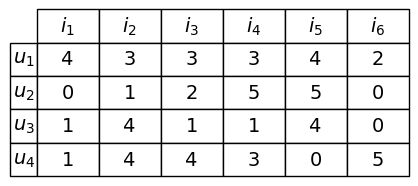

In [2]:
plot_rating_matrix(m = 6, n = 4)

# Formalización del modelo

- Estimar una función que automáticamente prediga que tanto le gustará un producto a un usuario, basándose en: comportamiento pasado, relaciones con otros usuarios, características del producto, etc.
- Sea $f$ una función que mide la **utilidad** de un producto $i$ en un usuario $u$, $f:U \times I \rightarrow R$, donde $R$ es un conjunto ordenado.
- Para cada usuario $u \in U$, se busca el producto $i \in I$ que maximiza $f$: 

$$ \forall u \in U, i'_{u} = \mbox{argmax}_{i \in I}(f(u,i))  $$

# Clasificación de los sistemas de recomendación


<div align="center">
<img src="img/recsys.png" alt="" width="80%" align="center" />
</div>

# Filtrado Colaborativo

Se basa en el algoritmo de los K vecinos más cercanos (KNN) para encontrar usuarios similares y utilizar sus preferencias para predecir.

El principio detrás de los métodos del vecino más cercano es encontrar un número predefinido de muestras de entrenamiento más cercanas en distancia al nuevo punto y predecir la etiqueta a partir de ellas.

# KNeighborsClassifier

Encuentra los K vecinos más cercanos al punto de prueba y lo clasifica según la clase predominante en el vecindario.

In [3]:
X, y = make_blobs(n_samples=10, centers=3, n_features=2, random_state=0)

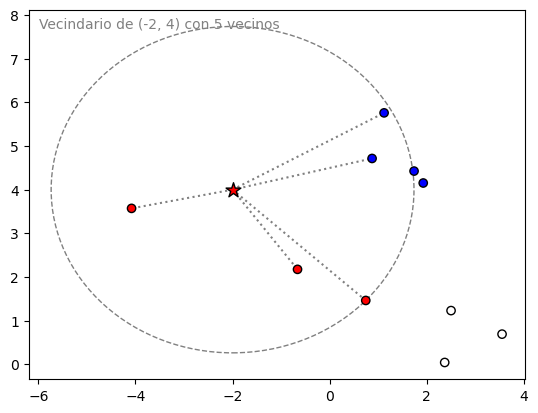

In [4]:
plot_knn(X, y, new=(-2,4), weights='uniform', nn=5)

# User k-NN (User-based CF)

Para predecir el rating $r$ sobre el producto $i$, se pueden promediar los ratings que los vecinos más cercanos (usuarios dentro del vecindario $\mathcal{N}$), le han entregado al producto $i$:

$$ \hat{r}(i) = \frac{\sum\limits_{u \in \mathcal{N}} r(u,i) }{ |\mathcal{N}| } $$

Si un usuario no ha evaluado el producto $i$ se deja fuera del vecindario. También se pueden ponderar los ratings según cercanía con el usuario al cual se le predice ($a$):

$$ \hat{r}(i) = \frac{\sum\limits_{u \in \mathcal{N}} r(u,i) \cdot \mbox{sim}(u,a)  }{ \sum\limits_{u \in \mathcal{N}} |\mbox{sim}(u,a)| } $$

# Item k-NN (Item-based CF)

Misma idea que User-based, pero construye un vecindario de productos similares:

$$ \hat{r}(i) = \frac{\sum\limits_{j \in \mathcal{N}} r(a,j) \cdot \mbox{sim}(i,j)  }{ \sum\limits_{j \in \mathcal{N}} |\mbox{sim}(i,j)| } $$

# Recomendación matricial SVD

<div align="center">
<img src="img/svd.png" alt="" width="40%" align="center" />
</div>

La matriz $U$ asocia los gustos de los usuarios sobre factores latentes y $V$ relaciona factores latentes con productos. La predicción es simplemente el producto punto entre la fila del usuario en la matriz $U$ y la columna del producto en la matriz $V$:

 $$ \hat{r}(i) = U\sqrt{\Sigma^T}(a) \cdot \sqrt{\Sigma}V^T(i) $$

# Ejemplo de Sistema Recomendador

In [5]:
df_ratings = pd.read_csv("data/ratings.csv")
df_ratings

,user_id,movie_id,rating
0,0,50,5
1,0,172,5
2,0,133,1
3,196,242,3
4,186,302,3
...,...,...,...
99998,880,476,3
99999,716,204,5
100000,276,1090,1
100001,13,225,2


In [6]:
df_movies = pd.read_csv("data/movies.csv")
df_movies

,movie_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)
...,...,...
1677,1678,Mat' i syn (1997)
1678,1679,B. Monkey (1998)
1679,1680,Sliding Doors (1998)
1680,1681,You So Crazy (1994)


# Matriz de ratings

In [7]:
ratings_matrix = df_ratings.pivot_table(values='rating', index='user_id', columns='movie_id', fill_value=0)

In [8]:
ratings_matrix

movie_id,1,2,3,4,5,6,7,8,9,10,...,1673,1674,1675,1676,1677,1678,1679,1680,1681,1682
user_id,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,5,3,4,3,3,5,4,1,5,3,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
939,0,0,0,0,0,0,0,0,5,0,...,0,0,0,0,0,0,0,0,0,0
940,0,0,0,2,0,0,4,5,3,0,...,0,0,0,0,0,0,0,0,0,0
941,5,0,0,0,0,0,4,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# Transposición y normalización

In [9]:
X = ratings_matrix.T

In [10]:
X_norm = X - np.asarray([(np.mean(X, 1))]).T

In [11]:
X_norm

user_id,0,1,2,3,4,5,6,7,8,9,...,934,935,936,937,938,939,940,941,942,943
movie_id,,,,,,,,,,,,,,,,,,,,,
1,-1.856992,3.143008,2.143008,-1.856992,-1.856992,2.143008,2.143008,-1.856992,-1.856992,-1.856992,...,0.143008,1.143008,2.143008,-1.856992,2.143008,-1.856992,-1.856992,3.143008,-1.856992,-1.856992
2,-0.444915,2.555085,-0.444915,-0.444915,-0.444915,2.555085,-0.444915,-0.444915,-0.444915,-0.444915,...,3.555085,-0.444915,-0.444915,-0.444915,-0.444915,-0.444915,-0.444915,-0.444915,-0.444915,4.555085
3,-0.289195,3.710805,-0.289195,-0.289195,-0.289195,-0.289195,-0.289195,-0.289195,-0.289195,-0.289195,...,-0.289195,-0.289195,3.710805,-0.289195,-0.289195,-0.289195,-0.289195,-0.289195,-0.289195,-0.289195
4,-0.786017,2.213983,-0.786017,-0.786017,-0.786017,-0.786017,-0.786017,4.213983,-0.786017,-0.786017,...,4.213983,-0.786017,-0.786017,-0.786017,-0.786017,-0.786017,1.213983,-0.786017,-0.786017,-0.786017
5,-0.300847,2.699153,-0.300847,-0.300847,-0.300847,-0.300847,-0.300847,-0.300847,-0.300847,-0.300847,...,-0.300847,-0.300847,-0.300847,-0.300847,-0.300847,-0.300847,-0.300847,-0.300847,-0.300847,-0.300847
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1678,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,...,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059,-0.001059
1679,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,...,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178,-0.003178
1680,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,...,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119,-0.002119


# Descomposición en valores singulares

In [12]:
A = X_norm.T / np.sqrt(X_norm.shape[0] - 1)
U, S, V = np.linalg.svd(A)

In [13]:
k = 50
decomposed_matrix = V.T[:, :k]

In [14]:
pd.DataFrame(decomposed_matrix)

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,-0.060631,0.079479,-0.014087,-0.124197,0.101222,0.028670,-0.080913,0.080726,-0.072436,0.015279,...,0.058333,-0.066423,0.000107,-0.026229,-0.000916,-0.088649,-0.005786,0.061058,0.111010,-0.096729
1,-0.043318,0.047651,0.029415,0.039338,-0.013923,-0.009430,-0.013873,0.000014,0.072323,-0.051254,...,-0.052469,-0.011273,0.002845,-0.028370,-0.015464,-0.039350,-0.085020,0.014204,-0.035422,-0.026909
2,-0.019572,0.036094,-0.036349,0.018592,0.021966,-0.023741,-0.011973,-0.020776,-0.025423,-0.027937,...,-0.063449,0.054763,0.021358,-0.004159,0.049776,0.011555,0.000486,0.011556,-0.009408,-0.013336
3,-0.070902,0.016262,-0.014272,0.048508,0.003590,-0.038219,0.033176,0.002619,0.050826,-0.072467,...,-0.039728,0.048898,-0.015856,-0.067021,-0.042504,0.026727,0.016965,0.015045,-0.041517,0.005709
4,-0.023638,0.032410,-0.007092,0.019488,-0.004535,-0.009218,0.034003,-0.064697,-0.000555,0.043602,...,0.001569,0.025953,-0.000824,0.003612,-0.011119,-0.006912,-0.054241,-0.032922,0.044911,-0.014113
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1677,0.000075,0.000012,-0.000208,0.000397,-0.000710,0.000099,-0.000138,0.000362,-0.000303,0.000032,...,0.000377,0.000111,0.000048,0.000107,-0.000360,0.000016,0.000209,-0.000149,0.000234,-0.000005
1678,0.000224,0.000035,-0.000625,0.001191,-0.002129,0.000298,-0.000415,0.001086,-0.000909,0.000097,...,0.001131,0.000332,0.000144,0.000322,-0.001079,0.000049,0.000626,-0.000446,0.000702,-0.000015
1679,0.000150,0.000023,-0.000416,0.000794,-0.001420,0.000198,-0.000276,0.000724,-0.000606,0.000065,...,0.000754,0.000221,0.000096,0.000215,-0.000719,0.000033,0.000417,-0.000298,0.000468,-0.000010
1680,-0.000489,0.000271,0.000118,0.000449,-0.000121,0.000646,0.000491,0.000514,0.001387,0.000218,...,0.005027,0.003279,0.000264,0.003445,-0.002932,0.002864,0.001645,0.002205,0.001005,0.002084


# Matriz de similaridad

In [15]:
similarity_matrix = cosine_similarity(decomposed_matrix)

In [16]:
df_sim_matrix = pd.DataFrame(similarity_matrix, index = X.index, columns = X.index)

In [17]:
df_sim_matrix

movie_id,1,2,3,4,5,6,7,8,9,10,...,1673,1674,1675,1676,1677,1678,1679,1680,1681,1682
movie_id,,,,,,,,,,,,,,,,,,,,,
1,1.000000,0.013383,-0.005295,-0.150866,-0.004339,0.012304,0.250663,-0.004807,-0.029462,0.120441,...,-0.146449,-0.100091,-0.244235,-0.244235,-0.340462,0.204737,0.204737,0.204737,-0.005202,-0.002920
2,0.013383,1.000000,-0.047949,0.112469,0.173999,0.201384,-0.028648,-0.089694,-0.011503,-0.004070,...,-0.001357,-0.237316,-0.079347,-0.079347,0.059895,-0.269414,-0.269414,-0.269414,-0.009510,-0.024202
3,-0.005295,-0.047949,1.000000,0.012071,-0.096897,0.113904,0.103394,-0.372633,-0.112551,-0.033128,...,0.086933,0.024963,-0.064708,-0.064708,0.003155,-0.011734,-0.011734,-0.011734,-0.078506,0.349334
4,-0.150866,0.112469,0.012071,1.000000,-0.033249,-0.075378,0.137260,0.060047,0.005272,-0.020742,...,-0.201759,-0.054222,0.068281,0.068281,0.002441,-0.085756,-0.085756,-0.085756,-0.037115,-0.076118
5,-0.004339,0.173999,-0.096897,-0.033249,1.000000,-0.075454,-0.035309,0.043974,0.049081,-0.139091,...,-0.045588,0.091839,0.069823,0.069823,0.037988,-0.074980,-0.074980,-0.074980,0.034151,-0.030189
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1678,0.204737,-0.269414,-0.011734,-0.085756,-0.074980,0.007461,-0.082484,0.087302,-0.118745,-0.045517,...,0.011913,-0.149973,0.214106,0.214106,-0.151178,1.000000,1.000000,1.000000,0.157779,-0.038219
1679,0.204737,-0.269414,-0.011734,-0.085756,-0.074980,0.007461,-0.082484,0.087302,-0.118745,-0.045517,...,0.011913,-0.149973,0.214106,0.214106,-0.151178,1.000000,1.000000,1.000000,0.157779,-0.038219
1680,0.204737,-0.269414,-0.011734,-0.085756,-0.074980,0.007461,-0.082484,0.087302,-0.118745,-0.045517,...,0.011913,-0.149973,0.214106,0.214106,-0.151178,1.000000,1.000000,1.000000,0.157779,-0.038219


# Espacio latente

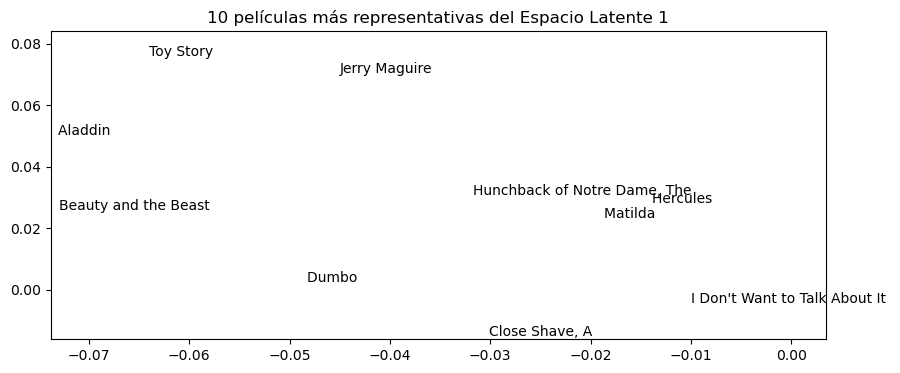

In [18]:
plot_latent_space(df_movies, df_sim_matrix, decomposed_matrix, factor=1, n=10)

# Recomendación Top-N

In [19]:
recomendar(df_movies, df_sim_matrix, titles=list(df_movies['title']))

interactive(children=(Dropdown(description='Película:', options=('Toy Story (1995)', 'GoldenEye (1995)', 'Four…